<a href="https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/08_evaluation_and_error_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 08 · Evaluation, error analysis and ablations
**Goal:** the fair, final comparison on the **test** set, plus an honest look at *where and why* the models fail. This is what the "documenting failures" deliverable.

**Contents:** (1) test table with bootstrap confidence intervals over utterances, (2) significance of improvement over the baseline, (3) error by phone, class, duration and context, (4) worst utterances, (5) feature-group ablation.

**Reads:** `features.csv.gz`, `preds_*.csv` from notebooks 06/07. **Writes:** `results/08_*`.

In [1]:
# ---- Cell 0: Setup (identical at the top of every notebook)
import os, sys, json, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
    IN_COLAB = True
except ImportError:                      # running somewhere else (local / tests)
    PROJECT_ROOT = os.environ.get('PROJECT_ROOT', os.getcwd())
    IN_COLAB = False
sys.path.insert(0, PROJECT_ROOT)
from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
A = cfg['audio']; P = cfg['abs_paths']
RAW, PROCESSED, ALIGN, SPLITS, RESULTS = P['raw'], P['processed'], P['alignments'], P['splits'], P['results']
for d in (PROCESSED, ALIGN, SPLITS, RESULTS):
    os.makedirs(d, exist_ok=True)
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Mounted at /content/drive
Project root: /content/drive/MyDrive/phonetic-tts | Colab: True


In [2]:
# ---- Write shared module: duration metrics
import os, importlib
_src = r'''"""Duration metrics. Durations are in mel frames (hop 256 @ 22,050 Hz = 11.61 ms per frame)."""
import numpy as np

FRAME_MS = 256 / 22050 * 1000


def summarize(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    err = p - y
    ss_res, ss_tot = (err ** 2).sum(), ((y - y.mean()) ** 2).sum()
    return {
        'mae_frames': float(np.abs(err).mean()),
        'mae_ms': float(np.abs(err).mean() * FRAME_MS),
        'rmse_frames': float(np.sqrt((err ** 2).mean())),
        'rmse_ms': float(np.sqrt((err ** 2).mean()) * FRAME_MS),
        'r2': float(1 - ss_res / ss_tot),
        'bias_frames': float(err.mean()),
        'n': int(len(y)),
    }
'''
_p = os.path.join(PROJECT_ROOT, "src/evaluation/metrics.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/evaluation/metrics.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/evaluation/metrics.py


In [3]:
# ---- Write shared module: feature column definitions
import os, importlib
_src = r'''"""Feature column definitions shared by notebooks 05-08 (and Phase 2 if you reuse the features)."""
CAT_COLS = ['base', 'stress_c', 'cls', 'prev1', 'prev2', 'next1', 'next2', 'word_punct']
NUM_COLS = ['pos_in_word', 'word_len', 'rel_pos_in_word', 'is_word_first', 'is_word_last',
            'word_idx', 'n_words', 'rel_pos_utt', 'seq_idx', 'n_phones', 'is_utt_final', 'is_utt_first',
            'pause_after', 'pause_before', 'is_vowel']
GROUPS = {
    'identity': ['base', 'stress_c', 'cls', 'is_vowel'],
    'context': ['prev1', 'prev2', 'next1', 'next2'],
    'word': ['pos_in_word', 'word_len', 'rel_pos_in_word', 'is_word_first', 'is_word_last'],
    'utterance': ['word_idx', 'n_words', 'rel_pos_utt', 'seq_idx', 'n_phones', 'is_utt_final', 'is_utt_first'],
    'pause_punct': ['pause_after', 'pause_before', 'word_punct'],
}
TARGET = 'dur_f'
'''
_p = os.path.join(PROJECT_ROOT, "src/features/feature_sets.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/features/feature_sets.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/features/feature_sets.py


In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.evaluation.metrics import summarize, FRAME_MS
from src.features.feature_sets import *
feat = pd.read_csv(os.path.join(PROCESSED, 'features.csv.gz'), keep_default_na=False, na_values=[''])
for c in CAT_COLS: feat[c] = feat[c].astype(str)
tr = pd.read_csv(os.path.join(PROCESSED, 'transcripts_clean.csv')).set_index('id')
P = {}
for f in sorted(glob.glob(os.path.join(RESULTS, 'preds_*.csv'))):
    d = pd.read_csv(f); d = d[d.split == 'test'].merge(feat[['row_id', 'utt_id', 'base', 'cls', 'pause_after', 'word_punct']], on='row_id')
    P[os.path.basename(f)[6:-4]] = d.sort_values('row_id').reset_index(drop=True)
print('models found:', list(P))

models found: ['bilstm', 'global_mean', 'hist_gbm', 'phone_mean_median', 'phone_stress_pause_backoff', 'ridge']


## 1. Test table with 95% bootstrap confidence intervals
We resample **utterances** (not phones) because phones within a sentence are not independent. Each resample recomputes MAE; the 2.5th and 97.5th percentiles give the interval.

In [5]:
rng = np.random.RandomState(0); B = 1000
utts = sorted(next(iter(P.values())).utt_id.unique()); u_idx = {u: i for i, u in enumerate(utts)}
samples = rng.randint(0, len(utts), size=(B, len(utts)))
def per_utt(d, col):
    s = d.groupby('utt_id')[col].agg(['sum', 'size']).reindex(utts); return s['sum'].values, s['size'].values
def boot_mae(d):
    s, n = per_utt(d.assign(ae=(d.y_pred - d.y_true).abs()), 'ae'); return s[samples].sum(1) / n[samples].sum(1)
rows, boots = [], {}
for name, d in P.items():
    m = summarize(d.y_true, d.y_pred); b = boot_mae(d); boots[name] = b
    rows.append(dict(model=name, mae_frames=m['mae_frames'], ci_low=np.percentile(b, 2.5), ci_high=np.percentile(b, 97.5),
                     mae_ms=m['mae_ms'], rmse_frames=m['rmse_frames'], r2=m['r2'], bias_frames=m['bias_frames']))
tab = pd.DataFrame(rows).sort_values('mae_frames'); tab.to_csv(os.path.join(RESULTS, '08_test_table.csv'), index=False); tab.round(3)

,model,mae_frames,ci_low,ci_high,mae_ms,rmse_frames,r2,bias_frames
0,bilstm,1.330,1.310,1.353,15.441,1.949,0.775,-0.137
2,hist_gbm,1.540,1.517,1.566,17.879,2.265,0.697,-0.360
5,ridge,2.013,1.987,2.043,23.373,2.877,0.511,-0.470
4,phone_stress_pause_backoff,2.220,2.193,2.248,25.778,3.122,0.424,-0.397
3,phone_mean_median,2.400,2.371,2.431,27.869,3.515,0.269,-0.683
1,global_mean,3.138,3.110,3.167,36.436,4.112,-0.000,-0.031


In [6]:
# ---- Is the best model *significantly* better than the phone-mean baseline? (paired bootstrap on the same resamples)
base_name = next((k for k in P if k.startswith('phone_mean')), tab.model.iloc[-1]); best_name = tab.model.iloc[0]
diff = boots[base_name] - boots[best_name]
print(f'{base_name} - {best_name}: MAE gain {diff.mean():.3f} frames, 95% CI [{np.percentile(diff, 2.5):.3f}, {np.percentile(diff, 97.5):.3f}]',
      '-> significant' if np.percentile(diff, 2.5) > 0 else '-> NOT significant')

phone_mean_median - bilstm: MAE gain 1.071 frames, 95% CI [1.048, 1.092] -> significant


## 2. Where does the best model fail?

In [7]:
d = P[best_name].assign(ae=lambda x: (x.y_pred - x.y_true).abs(), err=lambda x: x.y_pred - x.y_true)
bycls = d.groupby('cls').agg(n=('ae', 'size'), mae=('ae', 'mean'), bias=('err', 'mean'), mean_dur=('y_true', 'mean')); bycls['rel_mae'] = bycls.mae / bycls.mean_dur
byph = d.groupby('base').agg(n=('ae', 'size'), mae=('ae', 'mean'), bias=('err', 'mean'), mean_dur=('y_true', 'mean')).sort_values('mae', ascending=False)
bycls.to_csv(os.path.join(RESULTS, '08_per_class.csv')); byph.to_csv(os.path.join(RESULTS, '08_per_phone.csv'))
print(bycls.round(3)); print('\nworst phones:\n', byph.head(8).round(3))

               n    mae   bias  mean_dur  rel_mae
cls                                              
affricate    392  1.403 -0.174    10.462    0.134
fricative   6848  1.301 -0.158     8.338    0.156
glide       1099  1.188 -0.185     5.817    0.204
liquid      3096  1.340 -0.221     6.942    0.193
nasal       4170  1.230 -0.071     6.166    0.199
stop        7588  1.257 -0.089     7.378    0.170
vowel      14723  1.416 -0.149     7.674    0.184

worst phones:
          n    mae   bias  mean_dur
base                              
OY      35  2.205 -0.291    14.486
AY     487  2.146 -0.293    13.721
AE    1074  2.106 -0.282     9.361
AW     188  2.045 -0.053    14.989
OW     425  1.899 -0.331    11.045
AO     362  1.893  0.045     8.655
TH     185  1.782 -0.373     9.714
UW     426  1.776 -0.019     9.167


error by true duration (negative bias = under-prediction of long phones, shrinkage to the mean):
                n    mae   bias
y_true                        
(0, 3]      4856  0.934  0.875
(3, 5]      4800  0.828  0.352
(5, 8]     16027  1.094  0.123
(8, 12]     8135  1.533 -0.495
(12, 20]    3495  2.523 -1.772
(20, 400]    603  5.133 -4.794

by pause_after:
                  n    mae   bias
pause_after                     
0            35944  1.258 -0.131
1             1972  2.641 -0.239


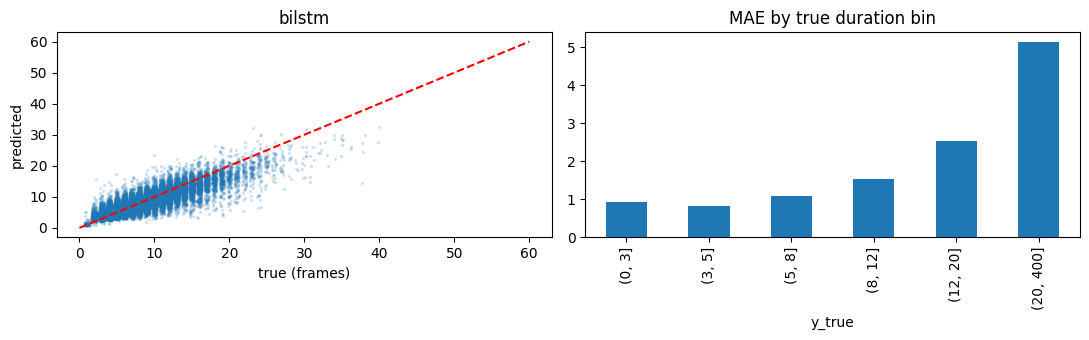

In [8]:
bins = pd.cut(d.y_true, [0, 3, 5, 8, 12, 20, 400]); bydur = d.groupby(bins, observed=True).agg(n=('ae', 'size'), mae=('ae', 'mean'), bias=('err', 'mean'))
bypause = d.groupby('pause_after').agg(n=('ae', 'size'), mae=('ae', 'mean'), bias=('err', 'mean'))
print('error by true duration (negative bias = under-prediction of long phones, shrinkage to the mean):\n', bydur.round(3)); print('\nby pause_after:\n', bypause.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].scatter(d.y_true.clip(upper=60) + np.random.RandomState(0).uniform(-.3, .3, len(d)), d.y_pred.clip(upper=60), s=2, alpha=.15)
ax[0].plot([0, 60], [0, 60], 'r--'); ax[0].set_xlabel('true (frames)'); ax[0].set_ylabel('predicted'); ax[0].set_title(best_name)
bydur['mae'].plot.bar(ax=ax[1]); ax[1].set_title('MAE by true duration bin'); plt.tight_layout()
plt.savefig(os.path.join(RESULTS, '08_error_analysis.png'), dpi=150); plt.show()

In [9]:
# ---- Worst utterances: read the text and ask WHY
u = d.groupby('utt_id').ae.mean().sort_values(ascending=False).head(10)
for uid, v in u.items(): print(f'{uid}  mean abs err {v:.2f} frames | {tr.loc[uid, "mfa_text"][:110]}')

LJ024-0071  mean abs err 3.17 frames | i propose that hereafter when a judge reaches the age of seventy
LJ017-0250  mean abs err 2.33 frames | from peru bound to bordeaux which had foundered at sea
LJ036-0073  mean abs err 2.10 frames | a bus moving through heavy traffic on elm from murphy to lamar was timed at four minutes
LJ024-0142  mean abs err 2.10 frames | i seek to make american democracy succeed
LJ028-0099  mean abs err 2.10 frames | the first born son of nabopolassar king of babylon am i
LJ028-0297  mean abs err 2.09 frames | how will thy disfigurement thou simpleton induce the enemy to yield one day sooner
LJ028-0298  mean abs err 2.08 frames | surely thou hadst gone out of thy mind when thou didst so misuse thyself
LJ028-0151  mean abs err 2.07 frames | leaving between them room for a four horse chariot to turn
LJ020-0069  mean abs err 2.07 frames | one even teaspoonful of salt
LJ010-0200  mean abs err 2.04 frames | young england which oxford had evolved out of his own infla



## 3. Ablation: which feature groups matter?
Retrain the gradient-boosted model with one group removed at a time, using the hyper-parameters chosen on val in notebook 06.

In [10]:
import json, time
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
bp = json.load(open(os.path.join(RESULTS, '06_best_params.json')))
trn, tst = feat[feat.split == 'train'], feat[feat.split == 'test']
def fit_eval(drop_groups, label):
    drop = set(c for g in drop_groups for c in GROUPS[g])
    cc = [c for c in CAT_COLS if c not in drop]; nc = [c for c in NUM_COLS if c not in drop]
    ct = ColumnTransformer([('c', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cc), ('n', 'passthrough', nc)])
    m = make_pipeline(ct, HistGradientBoostingRegressor(learning_rate=bp['hgb_lr'], max_iter=bp['hgb_iters'], categorical_features=list(range(len(cc))), random_state=0))
    t = time.time(); m.fit(trn, trn.log_dur); s = summarize(tst.dur_f, np.exp(m.predict(tst)))
    print(f'{label:28s} MAE {s["mae_frames"]:.3f} | R2 {s["r2"]:.3f} | {time.time()-t:.0f}s'); return dict(setting=label, mae_frames=s['mae_frames'], rmse_frames=s['rmse_frames'], r2=s['r2'])
abl = [fit_eval([], 'all features')] + [fit_eval([g], f'without {g}') for g in GROUPS]
abl.append(fit_eval(['context', 'word', 'utterance', 'pause_punct'], 'identity only'))
abl = pd.DataFrame(abl); abl['delta_mae_vs_all'] = abl.mae_frames - abl.mae_frames.iloc[0]
abl.to_csv(os.path.join(RESULTS, '08_ablation.csv'), index=False); abl.round(3)

all features                 MAE 1.540 | R2 0.697 | 45s
without identity             MAE 2.099 | R2 0.464 | 32s
without context              MAE 1.942 | R2 0.557 | 31s
without word                 MAE 1.601 | R2 0.674 | 34s
without utterance            MAE 1.534 | R2 0.699 | 32s
without pause_punct          MAE 1.654 | R2 0.618 | 34s
identity only                MAE 2.388 | R2 0.287 | 9s


,setting,mae_frames,rmse_frames,r2,delta_mae_vs_all
0,all features,1.540,2.265,0.697,0.000
1,without identity,2.099,3.011,0.464,0.559
2,without context,1.942,2.736,0.557,0.402
3,without word,1.601,2.349,0.674,0.061
4,without utterance,1.534,2.258,0.699,-0.006
5,without pause_punct,1.654,2.541,0.618,0.114
6,identity only,2.388,3.472,0.287,0.848
